In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import pandas as pd
import yaml

import numcosmo_II as nc

from datetime import datetime
from pathlib import Path

## Initial Configurations

In [2]:
current_dir  = Path.cwd()
project_root = current_dir.parent if current_dir.name == 'analysis' else current_dir
yaml_path = project_root / 'config' / "setup.yaml"

print( 100 * "=" )
print( "Loading Initial Setup" )
print( f"Project root set as: {project_root}" )
print( 100 * "=" + "\n" )

with open(yaml_path, "r", encoding = "utf-8" ) as config_file:
    config = yaml.safe_load( config_file )

print(f"{yaml.dump( config, sort_keys = False, allow_unicode = True ) }")

config_out   = config[ "output" ]
output_dir   = project_root / config_out["root"]
os.makedirs(output_dir, exist_ok=True)

timestamp     = datetime.now().strftime( "%Y%m%d_%H%M%S" )
base_filename = f"{config_out[ 'base_name' ]}_{timestamp}"
output_base   = output_dir / base_filename

Loading Initial Setup
Project root set as: /home/alex/Área de trabalho/Pós-Graduação/Disciplinas/Numerical_Cosmology_1/EP_II

cosmology:
  h: 0.6737
  Omega_b: 0.0493
  Omega_cdm: 0.2657
  Omega_m: 0.315
  Omega_r: 0.0
  Omega_lambda: 0.685
  w0_fld: -1.0
  wa_fld: 0.0
primordial:
  A_s: 2.1e-09
  n_s: 0.9649
  k_pivot: 0.05
growth:
  a_i: 0.0001
  a_f: 1.0
  num_points: 400
  solver:
    rtol: 1.0e-08
    atol: 1.0e-10
spt:
  box_size_L: 500.0
  grid_Ng: 128
  scale_factor_aref: 1.0
  pk_num_bins: 20
  bispectrum_num_bins: 12
  skewness:
    R_min: 4.0
    R_max: 12.0
    num_radii: 9
ensemble:
  num_realizations: 25
  seed_start: 12345
lpt:
  box_size_L: 200.0
  grid_Ng: 128
  scale_factor_aref: 1.0
  a_ini: 0.01
  a_target: 1.0
  seed: 42
  assignment_scheme: ngp
  pk_num_bins: 25
spherical_collapse:
  ai: 0.0001
  z_c: 0.0
  delta_i: 1e-4
  delta_stop: 1.0e4
  default_model: C
  f_i: 1.0
  n_points: 1000
  shooting:
    delta_i_min: 1.0e-08
    delta_i_max: 0.1
    tol: 1.0e-10
   

In [3]:
# _____ Cosmological Models & Parameters _____ #

cosmo_params = config[ "cosmology" ]
flrw_keys    = [ "h", "Omega_m", "Omega_r", "Omega_lambda", "w0_fld", "wa_fld" ]
flrw_params  = { k: cosmo_params[ k ] for k in flrw_keys if k in cosmo_params }

lcdm_model = nc.FLRW( **flrw_params )

eds_params = flrw_params.copy()
eds_params.update( {"Omega_m": 1.0, "Omega_lambda": 0.0, "Omega_r": 0.0} )
eds_model  = nc.FLRW( **eds_params )

ocdm_params = flrw_params.copy()
ocdm_params.update( {"Omega_m": flrw_params[ "Omega_m" ], "Omega_lambda": 0.0, "Omega_r": 0.0} )
ocdm_model  = nc.FLRW( **ocdm_params )

# _____ Primordial Spectrum Configuration _____ #

primordial_cfg = config[ "primordial" ]
A_s            = primordial_cfg[ "A_s" ]
n_s            = primordial_cfg[ "n_s" ]
k_pivot        = primordial_cfg[ "k_pivot" ]

In [4]:
# _____ Linear Growth Parameters _____ #

a_i = config[ "growth" ][ "a_i" ]
a_f = config[ "growth" ][ "a_f" ]

N_span = [ np.log( a_i ), np.log( a_f ) ]
N_eval = np.linspace( N_span[0], N_span[ 1 ], config[ "growth" ][ "num_points" ] )
a_eval = np.exp (N_eval )

growth_solver_opts = config[ "growth" ][ "solver" ]

In [5]:
# _____ Spherical Collapse Configurations _____ #

sc_cfg           = config[ "spherical_collapse" ]
sc_ai            = float( sc_cfg[ "ai" ] )
sc_zc            = float( sc_cfg[ "z_c"] )
sc_delta_i       = float( sc_cfg[ "delta_i" ] )
sc_delta_stop    = float( sc_cfg[ "delta_stop" ] )
sc_default_model = str ( sc_cfg[ "default_model" ] )
sc_fi            = float( sc_cfg[ "f_i" ] )
sc_n_points      = int( sc_cfg[ "n_points" ] )

sc_shooting_opts = sc_cfg[ "shooting" ]
sc_delta_i_min   = float( sc_shooting_opts[ "delta_i_min" ] )
sc_delta_i_max   = float( sc_shooting_opts[ "delta_i_max" ] )
sc_tol           = float( sc_shooting_opts[ "tol" ] )
sc_max_iter      = int(  sc_shooting_opts[ "max_iter" ] )

In [6]:
# _____ Spherical Collapse Cosmology _____ #

sc_lcdm = nc.SphericalCollapse( lcdm_model )
sc_eds  = nc.SphericalCollapse( eds_model )

ct_lcdm = nc.spherical_collapse.CollapseThreshold(
    sc_lcdm, model = sc_default_model, ai = sc_ai, delta_stop = sc_delta_stop, f_i = sc_fi, n_points = sc_n_points,
    delta_i_min = sc_delta_i_min, delta_i_max = sc_delta_i_max, tol = sc_tol, max_iter = sc_max_iter,
    )

ct_eds = nc.spherical_collapse.CollapseThreshold(
    sc_eds, model = sc_default_model, ai = sc_ai, delta_stop = sc_delta_stop, f_i = sc_fi, n_points = sc_n_points,
    delta_i_min = sc_delta_i_min, delta_i_max = sc_delta_i_max, tol = sc_tol, max_iter = sc_max_iter,
    )

## Spherical Collapse (Ex 4)

In [7]:
sol_eds  = eds_model.solve_growth(  N = N_span, y0 = [ a_i, a_i ], **growth_solver_opts)
sol_lcdm = lcdm_model.solve_growth( N = N_span, y0 = [ a_i, a_i ], **growth_solver_opts)
sol_ocdm = ocdm_model.solve_growth( N = N_span, y0 = [ a_i, a_i ], **growth_solver_opts)

D_eds,  f_eds  = eds_model.get_growth_observables(  sol_eds,  N_eval = N_eval )
D_lcdm, f_lcdm = lcdm_model.get_growth_observables( sol_lcdm, N_eval = N_eval )
D_ocdm, f_ocdm = ocdm_model.get_growth_observables( sol_ocdm, N_eval = N_eval )

In [8]:
f_i_exact = f_lcdm[ 0 ]

theta_i = -f_i_exact * sc_delta_i / ( 1.0 + sc_delta_i )
g_i     = 1.0 / sc_delta_i

print( f"Initial Scale Factor (sc_ai):   {sc_ai:.6e} (N_i = {np.log( sc_ai ):.4f})" )
print( f"Initial Overdensity (sc_delta_i):{sc_delta_i:.6e}" )
print( f"Exact Growth Rate f(sc_ai):     {f_i_exact:.6f}" )
print( f"Initial Velocity Div (theta_i): {theta_i:.6e}" )
print( f"Initial Inverse (g_i):          {g_i:.6e}\n" )

Initial Scale Factor (sc_ai):   1.000000e-04 (N_i = -9.2103)
Initial Overdensity (sc_delta_i):1.000000e-04
Exact Growth Rate f(sc_ai):     1.000000
Initial Velocity Div (theta_i): -9.999000e-05
Initial Inverse (g_i):          1.000000e+04



In [9]:
result = sc_lcdm.integrate( 
    ai = sc_ai, af = a_f, delta_i = sc_delta_i, f_i = f_i_exact, n_points = sc_n_points
    )

### Model Equivalence

In [10]:
a_traj = result[ "a" ]
sol_A  = result[ "Model_A" ]
sol_B  = result[ "Model_B" ]
sol_C  = result[ "Model_C" ]

delta_A = sol_A.y[ 0 ]
delta_B = sol_B.y[ 0 ]
g_C     = sol_C.y[ 0 ]
delta_C = 1.0 / g_C  

theta_B = sol_B.y[ 1 ]
theta_C = sol_C.y[ 1 ]

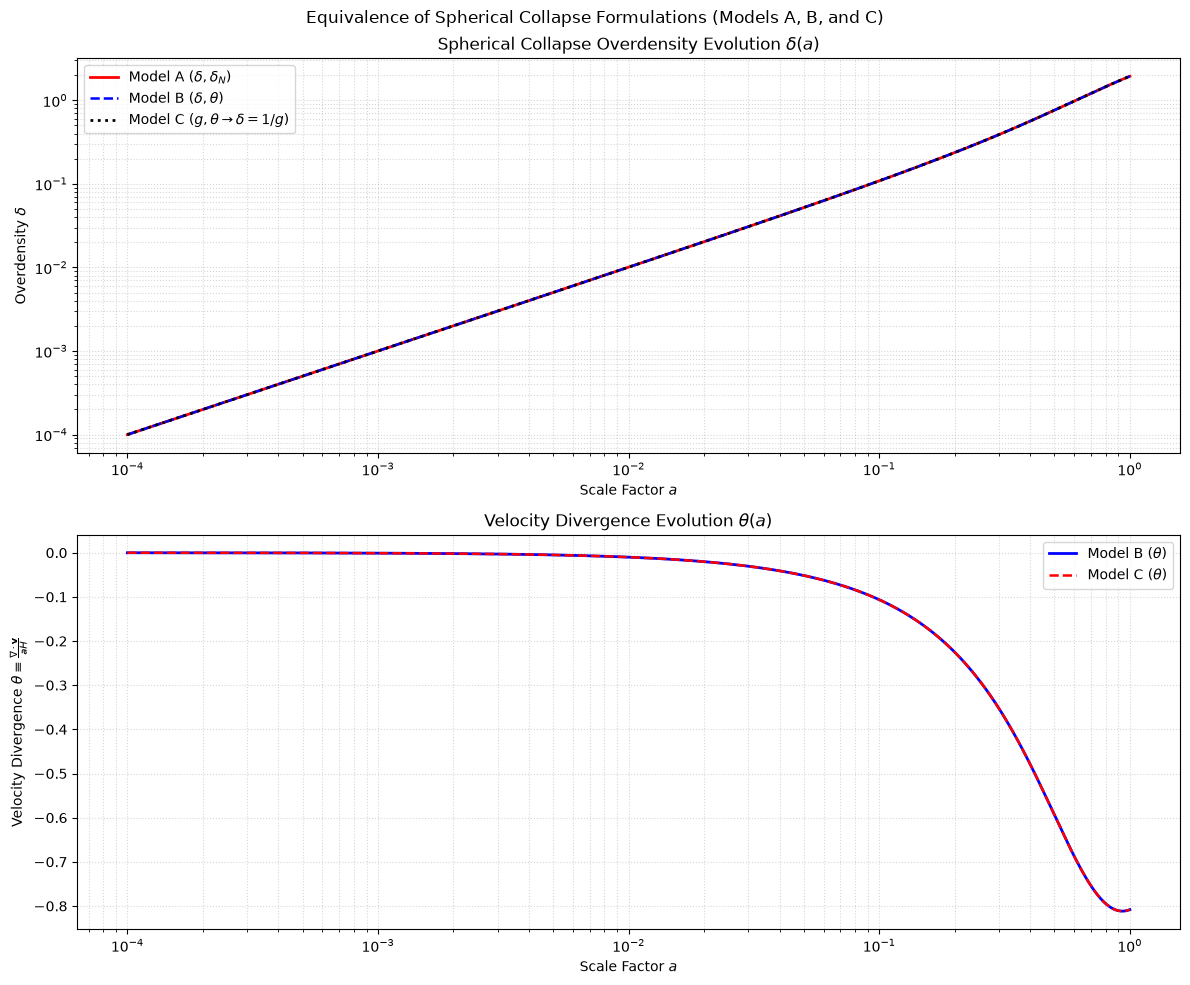

In [11]:
fig, axes = plt.subplots( 2, 1, figsize = ( 12, 10 ) )

axes[ 0 ].plot( a_traj, delta_A, 'r-',  lw = 2.0, label = r"Model A ($\delta, \delta_N$)" )
axes[ 0 ].plot( a_traj, delta_B, 'b--', lw = 1.8, label = r"Model B ($\delta, \theta$)" )
axes[ 0 ].plot( a_traj, delta_C, 'k:',  lw = 2.0, label = r"Model C ($g, \theta \to \delta=1/g$)" )
axes[ 0 ].set_xscale( "log" )
axes[ 0 ].set_yscale( "log" )
axes[ 0 ].set_xlabel( r"Scale Factor $a$" )
axes[ 0 ].set_ylabel( r"Overdensity $\delta$" )
axes[ 0 ].set_title( r"Spherical Collapse Overdensity Evolution $\delta(a)$" )
axes[ 0 ].grid( True, which = "both", ls = ":", alpha = 0.5 )
axes[ 0 ].legend()

axes[ 1 ].plot( a_traj, theta_B, 'b-',  lw = 2.0, label = r"Model B ($\theta$)" )
axes[ 1 ].plot( a_traj, theta_C, 'r--', lw = 1.8, label = r"Model C ($\theta$)" )
axes[ 1 ].set_xscale( "log" )
axes[ 1 ].set_xlabel( r"Scale Factor $a$" )
axes[ 1 ].set_ylabel( r"Velocity Divergence $\theta \equiv \frac{\nabla \cdot \mathbf{v}}{a H}$" )
axes[ 1 ].set_title( r"Velocity Divergence Evolution $\theta(a)$" )
axes[ 1 ].grid( True, which = "both", ls = ":", alpha = 0.5 )
axes[ 1 ].legend()

plt.suptitle( "Equivalence of Spherical Collapse Formulations (Models A, B, and C)", y = 0.98 )
plt.tight_layout()

plot_path_models = f"{output_base}_spherical_collapse_models.png"
plt.savefig( plot_path_models, dpi = 300, bbox_inches = "tight" )
plt.show()

In [12]:
diff_B = np.max( np.abs( ( delta_B - delta_A ) / delta_A ) )
diff_C = np.max( np.abs( ( delta_C - delta_A ) / delta_A ) )

print( 100 * "-" )
print( f"{'Model':<12} | {'delta(a_i)':<18} | {'delta(a_f)':<18} | {'Max Rel Diff vs Model A':<28}" )
print( 100 * "-" )
print( f"{'Model A':<12} | {delta_A[ 0 ]:<18.6e} | {delta_A[ -1 ]:<18.6e} | {'0.0 (Reference)':<28}" )
print( f"{'Model B':<12} | {delta_B[ 0 ]:<18.6e} | {delta_B[ -1 ]:<18.6e} | {diff_B:<28.4e}" )
print( f"{'Model C':<12} | {delta_C[ 0 ]:<18.6e} | {delta_C[ -1 ]:<18.6e} | {diff_C:<28.4e}" )
print( 100 * "-" + "\n" )

----------------------------------------------------------------------------------------------------
Model        | delta(a_i)         | delta(a_f)         | Max Rel Diff vs Model A     
----------------------------------------------------------------------------------------------------
Model A      | 1.000000e-04       | 1.939895e+00       | 0.0 (Reference)             
Model B      | 1.000000e-04       | 1.939895e+00       | 5.5159e-09                  
Model C      | 1.000000e-04       | 1.939894e+00       | 5.7892e-07                  
----------------------------------------------------------------------------------------------------



### Critical Collapse Threshold $\delta_c$ via Shooting Method

In [13]:
print( 100 * "=" )
print( "Calculating Linear Collapse Threshold delta_c via Shooting Method" )
print( 100 * "=" + "\n" )

delta_i_lcdm, delta_c_lcdm = ct_lcdm.find( z_c = sc_zc )
delta_i_eds,  delta_c_eds  = ct_eds.find(  z_c = sc_zc )

delta_c_eds_exact = 1.68647 

print( f"Target Collapse Redshift (z_c): {sc_zc:.2f}\n" )
print( f"Flat LCDM -> Initial delta_i: {delta_i_lcdm:.6e} | Critical delta_c: {delta_c_lcdm:.5f}" )
print( f"Flat EdS  -> Initial delta_i: {delta_i_eds:.6e}  | Critical delta_c: {delta_c_eds:.5f} (Analytical: {delta_c_eds_exact:.5f})" )
print( f"EdS Relative Error: {abs( delta_c_eds - delta_c_eds_exact ) / delta_c_eds_exact:.4e}\n" )


Calculating Linear Collapse Threshold delta_c via Shooting Method

Target Collapse Redshift (z_c): 0.00

Flat LCDM -> Initial delta_i: 2.113745e-04 | Critical delta_c: 1.66524
Flat EdS  -> Initial delta_i: 1.675176e-04  | Critical delta_c: 1.67518 (Analytical: 1.68647)
EdS Relative Error: 6.6967e-03



In [14]:
z_array        = np.linspace( 0.0, 3.0, 20 )
delta_c_lcdm_z = []
delta_c_eds_z  = []

for z in z_array:
    _, dc_l = ct_lcdm.find( z_c = z )
    _, dc_e = ct_eds.find(  z_c = z )
    delta_c_lcdm_z.append( dc_l )
    delta_c_eds_z.append( dc_e )

delta_c_lcdm_z = np.array( delta_c_lcdm_z )
delta_c_eds_z  = np.array( delta_c_eds_z )

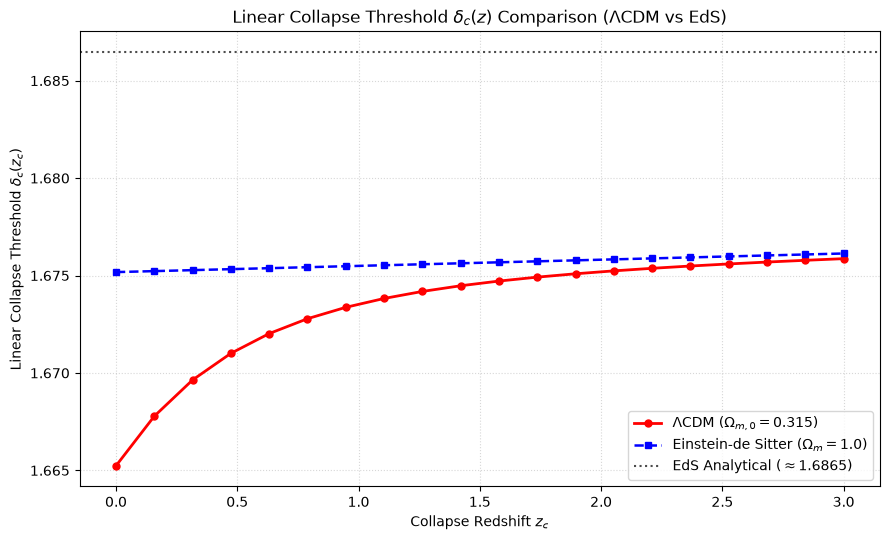

In [15]:
plt.figure( figsize = ( 9, 5.5 ) )
plt.plot( z_array, delta_c_lcdm_z, 'r-o', lw = 2.0, ms = 5, label = r"$\Lambda\mathrm{CDM}$ ($\Omega_{m,0}=0.315$)" )
plt.plot( z_array, delta_c_eds_z,  'b--s', lw = 1.8, ms = 5, label = r"Einstein-de Sitter ($\Omega_m=1.0$)" )
plt.axhline( delta_c_eds_exact, color = 'k', linestyle = ':', alpha = 0.7, label = r"EdS Analytical ($\approx 1.6865$)" )

plt.xlabel( r"Collapse Redshift $z_c$" )
plt.ylabel( r"Linear Collapse Threshold $\delta_c(z_c)$" )
plt.title( r"Linear Collapse Threshold $\delta_c(z)$ Comparison ($\Lambda\mathrm{CDM}$ vs EdS)" )
plt.grid( True, ls = ":", alpha = 0.5 )
plt.legend( )
plt.tight_layout()

plot_path_deltac = f"{output_base}_delta_c_redshift_evolution.png"
plt.savefig( plot_path_deltac, dpi = 300, bbox_inches = "tight" )
plt.show()

### $\delta_c(z_c)$ Validation between Models A, B e C

In [16]:
print( 100 * "=" )
print( "Comparing Linear Collapse Threshold delta_c across Models A, B, and C" )
print( 100 * "=" + "\n" )

models = [ "A", "B", "C" ]
redshifts = [ 0.0, 0.5, 1.0, 2.0, 3.0 ]

results = []

for model in models:
    for z_c in redshifts:

        threshold = nc.spherical_collapse.CollapseThreshold(
            sc_lcdm,
            model       = model,
            ai          = sc_ai,
            delta_stop  = sc_delta_stop,
            f_i         = f_i_exact,
            n_points    = sc_n_points,
            delta_i_min = sc_delta_i_min,
            delta_i_max = sc_delta_i_max,
            tol         = sc_tol,
            max_iter    = sc_max_iter,
        )

        delta_i, delta_c = threshold.find( z_c = z_c )

        results.append( {
            "Model":   model,
            "z_c":     z_c,
            "a_c":     1.0 / ( 1.0 + z_c ),
            "f_i":     f_i_exact,
            "delta_i": delta_i,
            "delta_c": delta_c,
        } )

results_df = pd.DataFrame( results )

Comparing Linear Collapse Threshold delta_c across Models A, B, and C



In [17]:
pivot = results_df.pivot( index = "z_c", columns = "Model", values = "delta_c" )

print( "Linear collapse thresholds delta_c(z_c):" )
print( 100 * "-" )
print( pivot.to_string() )
print( 100 * "-" + "\n" )

Linear collapse thresholds delta_c(z_c):
----------------------------------------------------------------------------------------------------
Model         A         B         C
z_c                                
0.0    1.665235  1.665235  1.665235
0.5    1.671197  1.671197  1.671197
1.0    1.673532  1.673532  1.673532
2.0    1.675192  1.675192  1.675192
3.0    1.675866  1.675866  1.675866
----------------------------------------------------------------------------------------------------



In [18]:
relative_difference = 100.0 * ( pivot.div( pivot[ "A" ], axis = 0 ) - 1.0 )

print( "Relative difference with respect to Model A (%):" )
print( 100 * "-" )
print( relative_difference.to_string() )
print( 100 * "-" + "\n" )

Relative difference with respect to Model A (%):
----------------------------------------------------------------------------------------------------
Model    A             B             C
z_c                                   
0.0    0.0  1.950495e-08  7.874401e-08
0.5    0.0  2.671097e-08  9.118186e-08
1.0    0.0  2.263481e-08  8.981784e-08
2.0    0.0  2.456415e-08  8.952707e-08
3.0    0.0  2.782656e-08  8.805077e-08
----------------------------------------------------------------------------------------------------



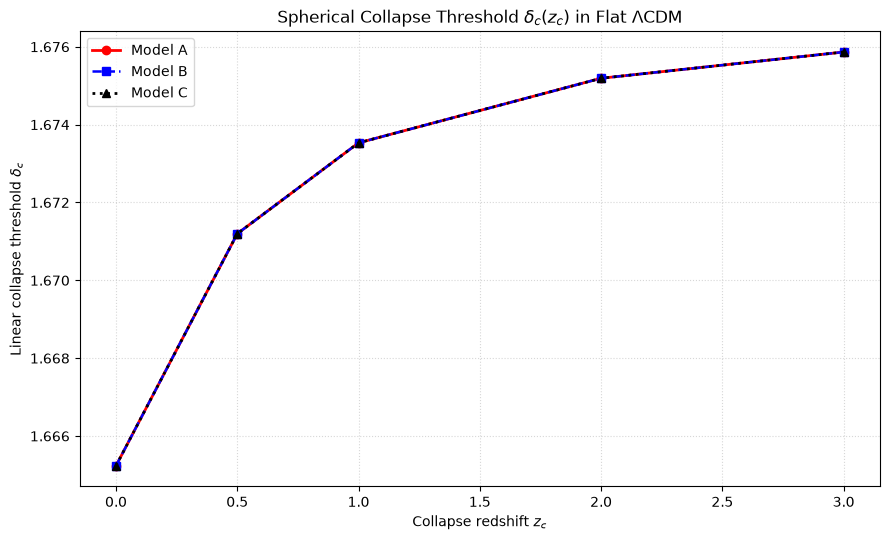

In [19]:
plt.figure( figsize = ( 9, 5.5 ) )

styles = { "A": ( "r-o", 2.0 ), "B": ( "b--s", 1.8 ), "C": ( "k:^", 2.0 ) }

for model in models:
    subset = results_df[ results_df[ "Model" ] == model ]
    fmt, lw = styles[ model ]
    plt.plot(
        subset[ "z_c" ],
        subset[ "delta_c" ],
        fmt,
        lw     = lw,
        ms     = 6,
        label  = f"Model {model}",
    )

plt.xlabel( r"Collapse redshift $z_c$" )
plt.ylabel( r"Linear collapse threshold $\delta_c$" )
plt.title( r"Spherical Collapse Threshold $\delta_c(z_c)$ in Flat $\Lambda\mathrm{CDM}$" )
plt.grid( True, ls = ":", alpha = 0.5 )
plt.legend()
plt.tight_layout()

plot_path_models_zc = f"{output_base}_models_delta_c_comparison.png"
plt.savefig( plot_path_models_zc, dpi = 300, bbox_inches = "tight" )
plt.show()